In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

# Logistic Regression - Breast Cancer Wisconsin Dataset

## Binary Classification

This project applies Logistic Regression for binary classification
using five optimization algorithms:

1. GD with Momentum
2. SGD with Momentum
3. Mini-Batch GD with Momentum
4. RMSProp with Momentum
5. Adam

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

In [8]:
from sklearn.datasets import load_breast_cancer

# Load Breast Cancer Wisconsin Diagnostic Dataset
data = load_breast_cancer()

X = data.data
y = data.target

In [9]:
print("Dataset name: Breast Cancer Wisconsin Diagnostic Dataset")
print("Number of samples:", X.shape[0])
print("Number of features:", X.shape[1])
print("Target classes:", np.unique(y))

Dataset name: Breast Cancer Wisconsin Diagnostic Dataset
Number of samples: 569
Number of features: 30
Target classes: [0 1]


In [10]:
print("Target names:", data.target_names)

print("\nFirst 10 target values:")
print(y[:10])

print("\nClass distribution:")
print(pd.Series(y).value_counts())

Target names: ['malignant' 'benign']

First 10 target values:
[0 0 0 0 0 0 0 0 0 0]

Class distribution:
1    357
0    212
Name: count, dtype: int64


In [11]:
# Split the dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 455
Testing samples: 114


In [12]:
# Standardize the features

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training data shape:", X_train_scaled.shape)
print("Testing data shape:", X_test_scaled.shape)

Training data shape: (455, 30)
Testing data shape: (114, 30)


In [13]:
# Sigmoid function

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

In [14]:
# Initialize weights and bias

n_features = X_train_scaled.shape[1]

weights = np.zeros(n_features)
bias = 0.0

print("Number of weights:", len(weights))
print("Initial bias:", bias)

Number of weights: 30
Initial bias: 0.0


In [16]:
# Binary Cross-Entropy Loss

def compute_loss(y_true, y_pred):
    epsilon = 1e-15
    y_pred = np.clip(y_pred, epsilon, 1 - epsilon)

    loss = -np.mean(
        y_true * np.log(y_pred) +
        (1 - y_true) * np.log(1 - y_pred)
    )

    return loss

In [18]:
# Forward pass

def predict_probability(X, weights, bias):
    z = np.dot(X, weights) + bias
    return sigmoid(z)

In [19]:
# Gradient Descent with Momentum

def train_gd_momentum(X, y, learning_rate=0.01, epochs=1000, momentum=0.9):
    
    n_samples, n_features = X.shape
    
    weights = np.zeros(n_features)
    bias = 0.0
    
    velocity_w = np.zeros(n_features)
    velocity_b = 0.0
    
    loss_history = []

    for epoch in range(epochs):
        
        # Forward pass
        y_pred = predict_probability(X, weights, bias)
        
        # Compute loss
        loss = compute_loss(y, y_pred)
        loss_history.append(loss)
        
        # Calculate gradients
        dw = (1 / n_samples) * np.dot(X.T, (y_pred - y))
        db = (1 / n_samples) * np.sum(y_pred - y)
        
        # Update velocity using momentum
        velocity_w = momentum * velocity_w - learning_rate * dw
        velocity_b = momentum * velocity_b - learning_rate * db
        
        # Update weights and bias
        weights += velocity_w
        bias += velocity_b

    return weights, bias, loss_history

In [20]:
# Train the model using GD with Momentum

weights_gd, bias_gd, loss_gd = train_gd_momentum(
    X_train_scaled,
    y_train,
    learning_rate=0.01,
    epochs=1000,
    momentum=0.9
)

print("Final Training Loss:", loss_gd[-1])

Final Training Loss: 0.061162421715233166


In [21]:
# Make predictions on the test data

y_test_prob = predict_probability(
    X_test_scaled,
    weights_gd,
    bias_gd
)

# Convert probabilities to binary classes
y_test_pred = (y_test_prob >= 0.5).astype(int)

print("First 10 predicted probabilities:")
print(y_test_prob[:10])

print("\nFirst 10 predicted classes:")
print(y_test_pred[:10])

First 10 predicted probabilities:
[8.98889893e-01 1.85683162e-05 3.89860043e-03 9.98842234e-01
 9.99909227e-01 1.03043070e-10 3.43507941e-09 4.28226526e-02
 6.58602913e-01 9.99066025e-01]

First 10 predicted classes:
[1 0 0 1 1 0 0 0 1 1]


In [22]:
# Calculate evaluation metrics

accuracy = accuracy_score(y_test, y_test_pred)
precision = precision_score(y_test, y_test_pred)
recall = recall_score(y_test, y_test_pred)
f1 = f1_score(y_test, y_test_pred)

test_loss = compute_loss(y_test, y_test_prob)

print("GD with Momentum Results")
print("------------------------")
print(f"Test Loss: {test_loss:.4f}")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1:.4f}")

GD with Momentum Results
------------------------
Test Loss: 0.0567
Accuracy:  0.9825
Precision: 0.9859
Recall:    0.9859
F1 Score:  0.9859


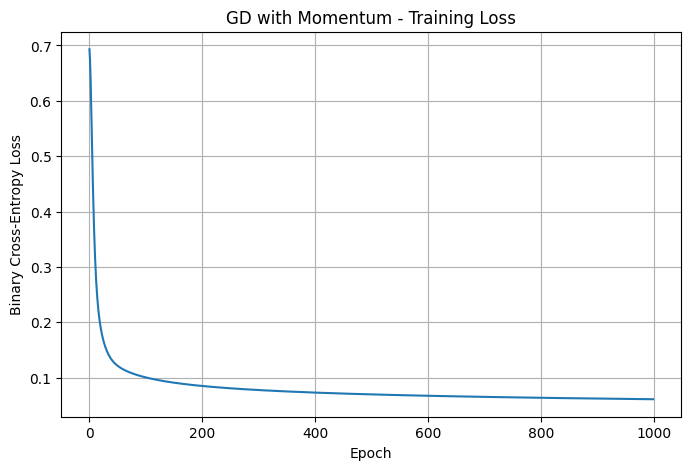

In [25]:
# Plot Training Loss

plt.figure(figsize=(8, 5))

plt.plot(loss_gd)

plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.title("GD with Momentum - Training Loss")

plt.grid(True)
plt.show()